# 02 · Orientación local antes de agrupar
PCA local busca la dirección e1 de mayor variación; su signo no tiene significado. Con λ1≥λ2≥λ3 calculamos linealidad=(λ1−λ2)/λ1, planaridad=(λ2−λ3)/λ1 y esfericidad=λ3/λ1. Para planos usamos la normal e3, porque e1 puede rotar dentro de una superficie plana.

Probamos k y umbrales de forma en la misma muestra voxel. Luego DBSCAN/HDBSCAN se ajustan por orientación. Otro/ruido crece hacia un segmento solo si está cerca; el resto se agrupa para no perder equipos aislados. Dos fusiones reúnen fragmentos colineales del mismo eje, antes y después del crecimiento. La segunda permite unir una cara planar con un fuste lineal si su PCA de instancia confirma ese eje. Se limita el tamaño menor del par a 1200 representantes, la distancia transversal y el hueco longitudinal. No basta que dos objetos se toquen.

La selección preliminar busca una zona con mezcla voxel<25%, ≥6 columnas altas y menos segmentos: no depende de silhouette. Los porcentajes de esta sensibilidad son voxel, no porcentajes finales de la nube.

**Ejecución:** IPython en `.venv`, celdas en orden, sin kernel de sockets (nbconvert bloqueado por sandbox). Tiempo: 23.23 s. Logs en `outputs/logs/`; cachés en `outputs/cache/`.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.dont_write_bytecode = True
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0,str(ROOT/'src'))
os.environ['MPLCONFIGDIR']=str(ROOT/'outputs/cache/exp_matplotlib')
os.environ['IPYTHONDIR']=str(ROOT/'outputs/cache/exp_ipython')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, build_features
from pcseg.metrics import silhouette_sample, davies_bouldin
from pcseg.stages import *
plt.switch_backend('Agg')
thread_limit = threadpool_limits(limits=2)
OUT=ROOT/'outputs'; CACHE=OUT/'cache'; FIG=OUT/'figs'; LOG=OUT/'logs'; ENT=ROOT/'entregable'; ENT.mkdir(exist_ok=True)
START=time.perf_counter()
cloud=read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
common_idx=np.load(OUT/'sample_idx.npy')
xyz,rgb,normals=(cloud[k][common_idx] for k in ('xyz','rgb','normals'))
EVAL=build_features(xyz,rgb,normals,use_rgb=True,use_normals=True,use_height=True)
base_table=pd.read_csv(ENT/'clase_metricas.csv')
base=base_table[base_table.seleccionada].iloc[0]
base_labels=np.load(LOG/'clase_labels'/f'{base.id}.npy')
assert len(xyz)==93903 and len(cloud['xyz'])==1647021
print('Muestra común',len(xyz),'Python',sys.executable,sys.version.split()[0])
CLASS_COLORS={'piso':(70,155,70),'techo':(90,140,230),'pared':(190,145,90),
 'plano_horizontal':(145,190,220),'columna':(230,60,55),'viga_horizontal':(245,170,35),
 'viga_o_tuberia':(225,125,25),'tuberia':(25,180,185),
 'equipo_bajo':(155,75,190),'compacto_plausible':(30,200,190),
 'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45)}
def view(points,labels,name,title,classes=None):
    idx=np.random.default_rng(0).choice(len(points),min(35000,len(points)),replace=False)
    p=points[idx]; ls=labels[idx]
    if classes is None: colors=labels_to_rgb(ls)/255.
    else: colors=np.array([CLASS_COLORS[classes[int(v)]] for v in ls])/255.
    fig=plt.figure(figsize=(16,5))
    for i,j in enumerate((1,2)):
        ax=fig.add_subplot(1,3,i+1)
        ax.scatter(p[:,0],p[:,j],c=colors,s=2,alpha=.65,linewidths=0)
        ax.set(xlabel='x (m)',ylabel='y (m)' if j==1 else 'z (m)',aspect='equal',title='Superior' if j==1 else 'Lateral')
    ax=fig.add_subplot(1,3,3,projection='3d'); ax.scatter(*p.T,c=colors,s=1,alpha=.65)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D'); ax.set_box_aspect(np.maximum(np.ptp(p,axis=0),.1))
    if classes:
        names=sorted(set(classes.values()))
        fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255,label=n) for n in names],loc='lower center',ncol=4,fontsize=8)
    fig.suptitle(title); fig.tight_layout(rect=(0,.12,1,.94) if classes else (0,0,1,.94))
    path=FIG/f'exp_{name}.png'; fig.savefig(path,dpi=140); plt.close(fig); display(Image(filename=str(path)))
def save_run(name,run):
    np.savez_compressed(CACHE/f'exp_{name}.npz',labels=run['labels'],idx=run['idx'],sample_labels=run['sample_labels'])
    serial=[]
    for p in run['planes']:
        serial.append({k:v for k,v in p.items() if k!='inliers'})
    (CACHE/f'exp_{name}_planes.json').write_text(json.dumps(serial,indent=2))
    supports={f'plano_{j}':run['idx'][p['inliers']] for j,p in enumerate(run['planes'])}
    sampled=cloud['xyz'][run['idx']]
    for j,p in enumerate(run['planes']):
        for k,coef in enumerate(p.get('patches',[])):
            mask=np.abs(sampled@np.asarray(coef[:3])+coef[3])<.08
            supports[f'plano_{j}_parche_{k}']=run['idx'][mask]
    np.savez_compressed(CACHE/f'exp_{name}_inliers.npz',**supports)
def load_run(name):
    a=dict(np.load(CACHE/f'exp_{name}.npz'))
    a['planes']=json.loads((CACHE/f'exp_{name}_planes.json').read_text())
    return a
def finish(name, payload):
    payload['segundos_notebook']=time.perf_counter()-START
    (CACHE/f'exp_resumen_{name}.json').write_text(json.dumps(payload,indent=2,default=float))
    print(payload)

from pcseg.propagate import propagate_labels
from sklearn.preprocessing import StandardScaler
BASE_FULL=propagate_labels(xyz,base_labels,cloud['xyz'])
def maps_and_totals(run):
    desc,totals=summarize_classes(cloud['xyz'],run['labels'],run['planes'])
    classes=dict(zip(desc.id,desc.clase_heuristica)); classes[-1]='ruido'
    return desc,totals,classes
def mixture_metrics(desc,totals):
    def pct(name):
        row=totals[totals.clase_heuristica==name]
        return float(row.porcentaje.sum())
    columns=desc[desc.clase_heuristica=='columna']
    high=columns[columns.extension_vertical>=5]
    from sklearn.cluster import DBSCAN
    xy=(high[['x_min','y_min']].to_numpy()+high[['x_max','y_max']].to_numpy())/2
    footprints=DBSCAN(eps=1.5,min_samples=1).fit_predict(xy) if len(high) else []
    distinct=len(set(footprints))
    return dict(n_segmentos_completo=int((desc.id>=0).sum()),mezcla_pct=pct('mezcla_no_identificada'),ruido_completo_pct=pct('ruido'),
        no_resuelto_pct=pct('mezcla_no_identificada')+pct('ruido'),
        n_columnas=int(len(columns)),n_columnas_altas=int((columns.extension_vertical>=5).sum()),n_columnas_altas_distintas=distinct)
def geometry_space():
    path=CACHE/'exp_features_geo.npy'
    if path.exists(): return np.load(path)
    f=local_pca_features(xyz,k=96)
    X=StandardScaler().fit_transform(np.c_[xyz,normals,f['linealidad']])
    np.save(path,X)
    return X


Muestra común 93903 Python /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


,nombre,k,n_segmentos_completo,mezcla_pct,ruido_completo_pct,no_resuelto_pct,n_columnas,n_columnas_altas,n_columnas_altas_distintas,n_segmentos,parametros
0,k24,24,633,15.747040,0.849368,16.596408,37,11,11,633,"{""k"": 24, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
1,k48,48,649,9.872421,0.895975,10.768396,37,16,15,649,"{""k"": 48, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
2,k96,96,664,6.763638,0.908496,7.672134,40,18,16,664,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
3,linear0.3,96,661,7.001544,0.839629,7.841173,39,20,17,661,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
4,linear0.6,96,569,9.139920,0.940496,10.080415,36,17,13,569,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
5,planar0.35,96,660,10.779526,0.861889,11.641415,36,17,15,660,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
6,planar0.65,96,626,6.406778,0.864672,7.271450,42,18,17,626,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
7,crecer0.25,96,730,9.619906,1.035102,10.655008,36,16,15,730,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
8,crecer0.65,96,585,6.127134,0.593375,6.720509,35,18,17,585,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."
9,fusion0.35,96,963,6.787985,0.908496,7.696481,57,19,13,963,"{""k"": 96, ""method"": ""dbscan"", ""eps"": 0.35, ""mi..."


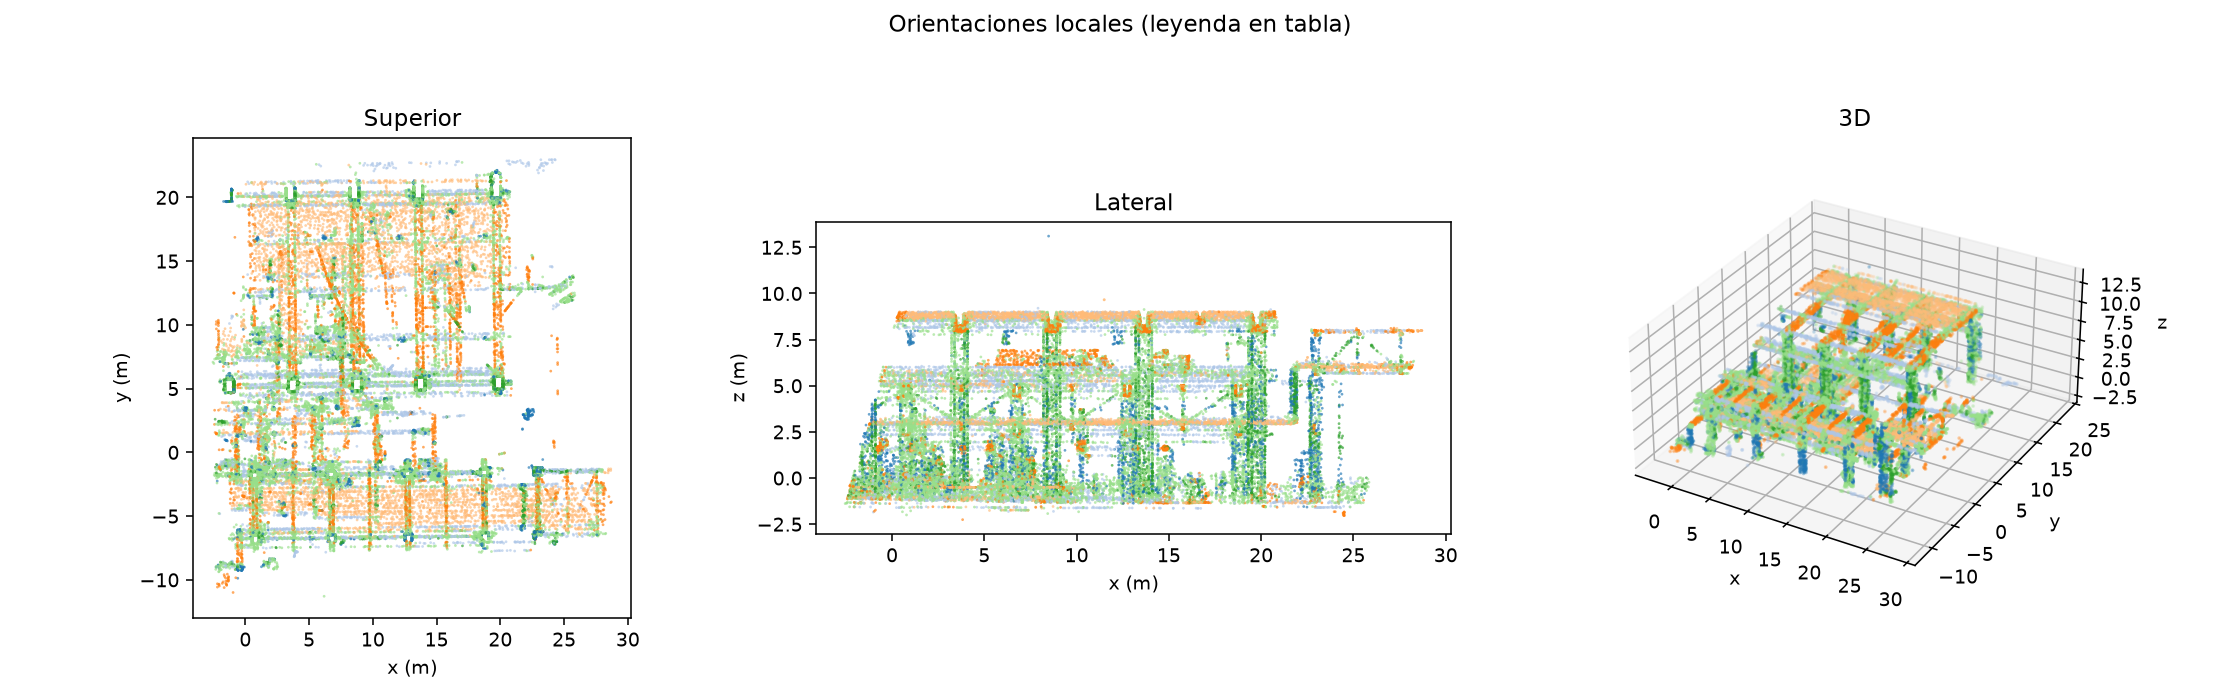

,id,orientacion
0,0,lineal_vertical
1,1,lineal_horizontal_x
2,2,lineal_horizontal_y
3,3,planar_normal_vertical
4,4,planar_normal_horizontal
5,5,otro


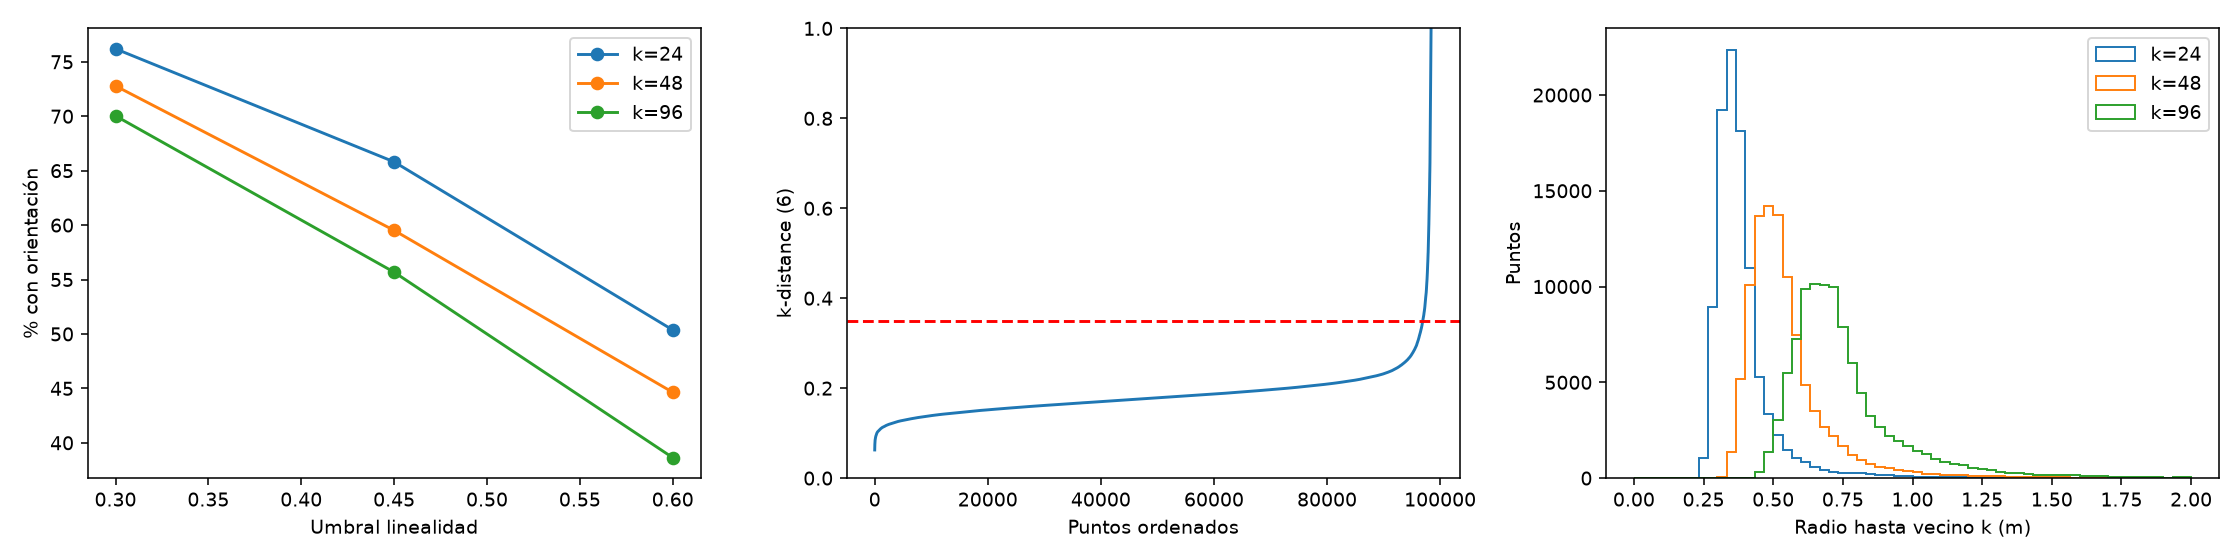

,clase_heuristica,n_segmentos,n_puntos,porcentaje
0,columna,38,212863,12.924122
1,compacto_plausible,180,59703,3.624908
2,equipo_bajo,48,34309,2.083094
3,mezcla_no_identificada,98,124827,7.578956
4,piso,1,488252,29.644552
5,ruido,1,6956,0.422338
6,techo,1,111522,6.771134
7,viga_horizontal,97,285877,17.357216
8,viga_o_tuberia,201,322712,19.593679


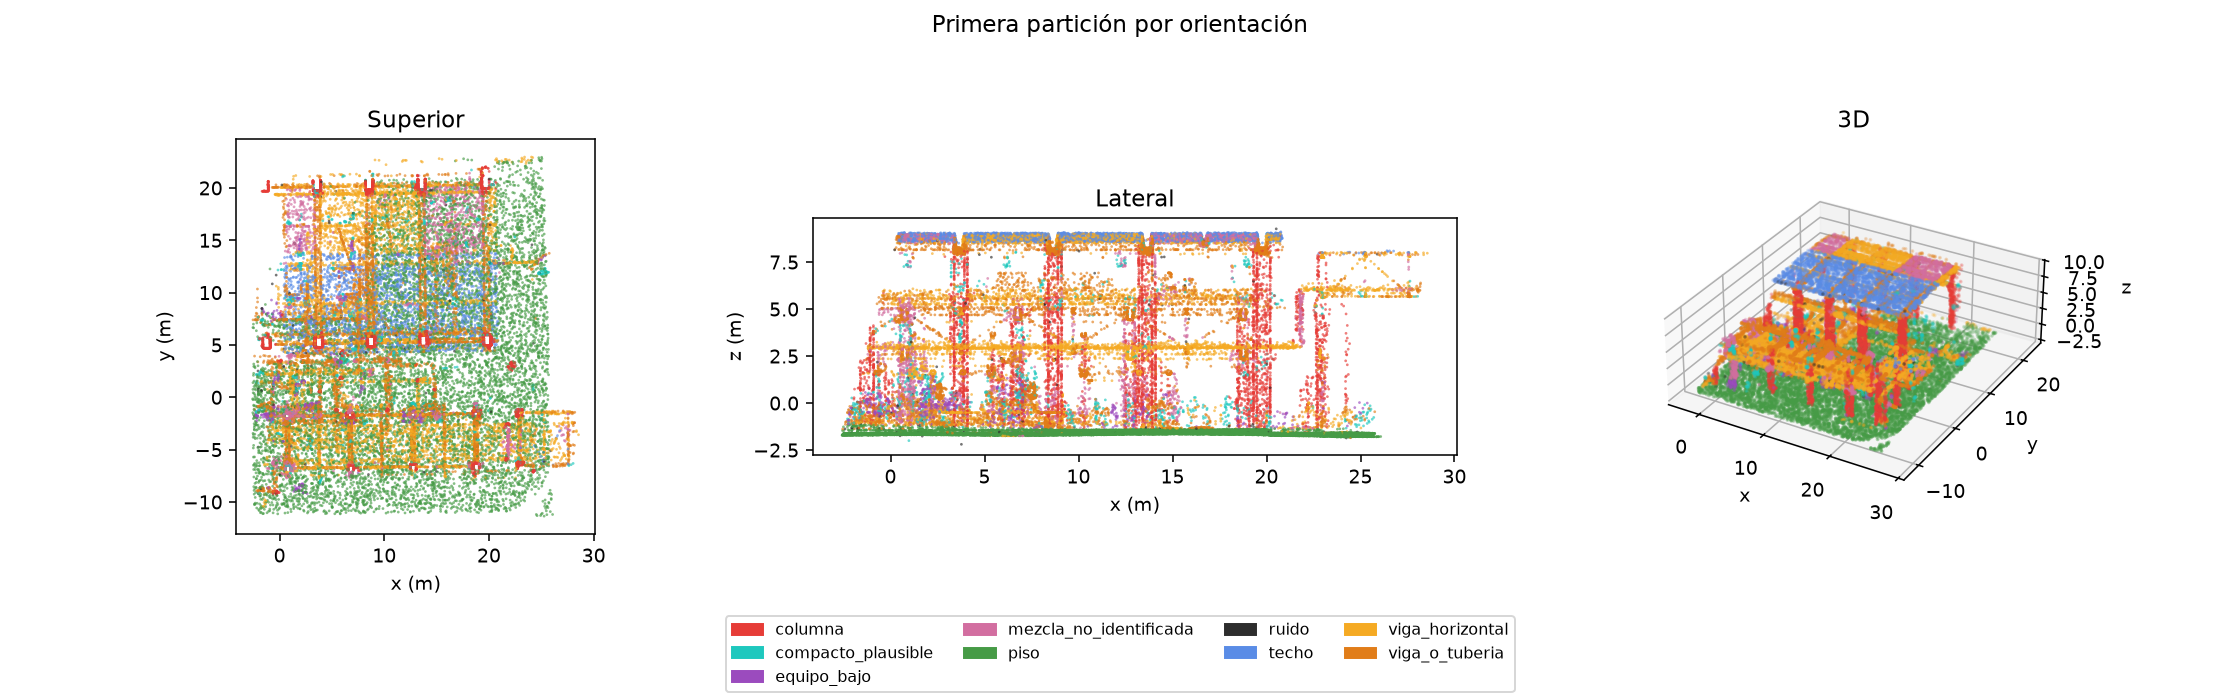

{'n_segmentos_completo': 664, 'mezcla_pct': 7.578956188172464, 'ruido_completo_pct': 0.42233827012527464, 'no_resuelto_pct': 8.001294458297739, 'n_columnas': 38, 'n_columnas_altas': 18, 'n_columnas_altas_distintas': 16, 'configuracion': {'voxel': 0.15, 'k': 96, 'linear_threshold': 0.45, 'planar_threshold': 0.5, 'eps': 0.35, 'min_samples': 6, 'reassign_distance': 0.45, 'merge_gap': 1.2, 'merge_lateral': 0.75}, 'n_segmentos': 664, 'segundos_notebook': 24.617586239000957}


In [2]:
structure=load_run('estructura');idx=structure['idx'];planes=structure['planes']
p=cloud['xyz'][idx];plabel=assign_planes(p,planes,.08);residual=plabel<0;q=p[residual]
shape_rows=[];trial_rows=[];feature_cache={}
for k in (24,48,96):
    f=local_pca_features(q,k);feature_cache[k]=f
    for linear in (.30,.45,.60):
        for planar in (.35,.50,.65):
            group=orientation_classes(f,linear,planar)
            row=dict(k=k,linealidad=linear,planaridad=planar,radio_mediana=float(np.median(f['radio'])))
            for name in ORIENTATION_NAMES:row[name]=100*np.mean(group==name)
            shape_rows.append(row)
shapes=pd.DataFrame(shape_rows);shapes.to_csv(OUT/'exp_sensibilidad_orientacion.csv',index=False)
# Un factor por vez alrededor de la configuración de referencia.
trials=[dict(nombre=f'k{k}',k=k) for k in (24,48,96)]
trials += [dict(nombre=f'linear{v}',k=96,linear_threshold=v) for v in (.30,.60)]
trials += [dict(nombre=f'planar{v}',k=96,planar_threshold=v) for v in (.35,.65)]
trials += [dict(nombre=f'crecer{v}',k=96,reassign_distance=v) for v in (.25,.65)]
trials += [dict(nombre=f'fusion{lat}',k=96,merge_lateral=lat,merge_gap=gap) for lat,gap in ((.35,.4),(.55,.85),(.75,1.2))]
trials += [dict(nombre='HDBSCAN',k=96,method='hdbscan',min_cluster_size=40),
           dict(nombre='kmeans_por_orientacion',k=96,method='kmeans'),
           dict(nombre='xy_z_por_orientacion',k=96,method='two_level')]
for options in trials:
    name=options['nombre'];k=options['k'];kwargs={key:value for key,value in options.items() if key not in ('nombre','k')}
    params=dict(method='dbscan',eps=.35,min_samples=6,linear_threshold=.45,planar_threshold=.50,
        reassign_distance=.45,merge_gap=1.2,merge_lateral=.75)
    params.update(kwargs)
    lab,groups,detail=cluster_orientations(q,feature_cache[k],**params)
    labels=plabel.copy();labels[residual]=np.where(lab<0,-1,lab+len(planes))
    desc,totals=summarize_classes(p,labels,planes);met=mixture_metrics(desc,totals)
    trial_rows.append(dict(nombre=name,k=k,**met,n_segmentos=len(desc[desc.id>=0]),
        parametros=json.dumps(dict(k=k,**params))))
trials_table=pd.DataFrame(trial_rows);trials_table.to_csv(OUT/'exp_sensibilidad_agrupacion.csv',index=False);display(trials_table)
# La sensibilidad informa el ajuste; no se usa la mezcla sola para premiar descarte.
# Preferimos perfiles de radio y cantidad de fragmentos estables, con crecimiento acotado.
params=dict(voxel=.15,k=96,linear_threshold=.45,planar_threshold=.50,eps=.35,min_samples=6,
    reassign_distance=.45,merge_gap=1.2,merge_lateral=.75)
(CACHE/'exp_config_referencia.json').write_text(json.dumps(params,indent=2))
f=feature_cache[96];groups=orientation_classes(f,.45,.50)
group_ids=np.array([ORIENTATION_NAMES.index(name) for name in groups],dtype=np.int32)
view(q,group_ids,'02_orientaciones','Orientaciones locales (leyenda en tabla)')
display(pd.DataFrame({'id':np.arange(len(ORIENTATION_NAMES)),'orientacion':ORIENTATION_NAMES}))
distance=cKDTree(q).query(q,k=6,workers=2)[0][:,-1]
fig,axes=plt.subplots(1,3,figsize=(16,4))
for k in (24,48,96):
    sub=shapes[(shapes.k==k)&(shapes.planaridad==.5)]
    axes[0].plot(sub.linealidad,100-sub.otro,'o-',label=f'k={k}')
axes[0].set(xlabel='Umbral linealidad',ylabel='% con orientación');axes[0].legend()
axes[1].plot(np.sort(distance));axes[1].axhline(.35,c='r',ls='--');axes[1].set(ylim=(0,1),ylabel='k-distance (6)',xlabel='Puntos ordenados')
for k in (24,48,96):axes[2].hist(feature_cache[k]['radio'],bins=60,range=(0,2),histtype='step',label=f'k={k}')
axes[2].set(xlabel='Radio hasta vecino k (m)',ylabel='Puntos');axes[2].legend()
path=FIG/'exp_02_sensibilidad.png';fig.tight_layout();fig.savefig(path,dpi=140);plt.close(fig);display(Image(filename=str(path)))
run=pipeline(cloud,cloud['xyz'],**params);save_run('referencia',run)
desc,totals,classes=maps_and_totals(run);totals.to_csv(OUT/'exp_referencia_clases.csv',index=False);display(totals)
view(cloud['xyz'],run['labels'],'02_referencia','Primera partición por orientación',classes)
finish('02',dict(**mixture_metrics(desc,totals),configuracion=params,n_segmentos=int((desc.id>=0).sum())))

## Qué aprendimos / qué falló
La sensibilidad ayudó a elegir un punto intermedio: con k=96 y planaridad=0.50, subir el umbral de linealidad de 0.30 a 0.45 y 0.60 deja **29.97%, 44.33% y 61.36%** en otro. El umbral alto pierde demasiados soportes; el bajo acepta direcciones con menos evidencia. Elegimos 0.45, sin llamarlo óptimo. El radio mediano de los 96 vecinos es **0.706 m**. En la sensibilidad voxel, k=24/48/96 dejó mezcla de **15.75/9.87/6.76%**. k grande mejora continuidad de los fustes, pero puede borrar detalles pequeños.

Planaridad 0.35/0.50/0.65 produjo mezcla voxel de **10.78/6.76/6.41%**; conservamos 0.50 como compromiso, no porque sea el mínimo aislado. Crecer 0.25/0.45/0.65 m dejó **9.62/6.76/6.13%** de mezcla; 0.45 evita ampliar otros 20 cm por una ganancia pequeña de este proxy. En fusión, el par (lateral=0.35, hueco=0.40) dejó **963 segmentos**, frente a **664** con (0.75,1.20). También bajaron las columnas candidatas voxel de 57 a 40: parte del conteo eran fragmentos. Todavía podemos fusionar soportes cercanos o dejar caras separadas.

La prueba xy→z no resuelve por sí sola la forma de los objetos. k-means por orientación dejó **58.36%** de mezcla voxel y ninguna columna bajo las reglas; cortar con centroides no garantiza fustes. Las cifras de esta sensibilidad son voxel y no deben confundirse con los porcentajes completos de 04/05.